# LSTM Music Generator

This project implements a sequence-to-sequence model to generate simple music melodies using a Bidirectional LSTM network in TensorFlow/Keras.

## Table of Contents
- [Project Overview](#project-overview)
- [Dataset](#dataset)
- [Model Architecture](#model-architecture)
- [Training & Performance](#training--performance)
- [Music Generation](#music-generation)
- [Observation: The Repetitive Note Loop](#observation-the-repetitive-note-loop)
- [Future Improvements](#future-improvements)

## Project Overview

The goal is to train a deep learning model capable of predicting sequential music notes. Given a starting seed of notes, the trained model generates a continuation sequence (melody) and visualizes the result as a piano roll.

## Dataset

We utilize a synthetic dataset designed to simulate sequence transitions:
- **Vocabulary Size (`num_notes`)**: 40 distinct pitch classes.
- **Sequence Length**: 25 notes.
- **Total Sequences (`num_sequences`)**: 1,200 samples.
- **Input (`x_train`)** and **Target (`y_train`)**: Created using a sliding window approach (`data[:, :-1]` as input, `data[:, 1:]` as the shifted target) and one-hot encoded.

## Model Architecture

The model is built using Keras' `Sequential` API:
1. **Input Layer**: Accepts batches with a sequence shape of `(24, 40)`.
2. **Bidirectional LSTM (100 units)**: Processes the sequence forwards and backwards to capture bidirectional dependencies.
3. **Bidirectional LSTM (100 units)**: Extracted features are processed through a second recurrent layer.
4. **TimeDistributed Dense (40 units, Softmax)**: Outlines output probabilities for each pitch at every step of the sequence.

## Training & Performance

- **Optimizer**: Adam (learning rate = 0.001)
- **Loss Function**: Categorical Crossentropy
- **Metrics**: Accuracy
- **Batch Size**: 64
- **Epochs**: 15

The model quickly reaches over 95% training and validation accuracy within 15 epochs, indicating that it has learned the transitions of the synthetic random dataset.

## Music Generation

Music is generated autoregressively:
1. Provide a seed sequence of 24 notes.
2. Predict the probability distribution of the next note using the model.
3. Extract the predicted note (currently using deterministic argmax selection).
4. Append the new note to the sequence, slide the input window forward by one step, and repeat.

## Observation: The Repetitive Note Loop

Currently, the generated music yields a sequence of identical repeated notes (e.g., repeating the pitch `26`). This behavior happens because:
- **Deterministic Sampling (`np.argmax`)**: Choosing only the highest probability note often leads the model into local attractors or repetitive loops.
- **Random Dataset**: Since the dataset is purely random numbers with no strong temporal structure or music grammar, the network quickly defaults to a safe, repeating global mode.

## Future Improvements

To make the generation more creative and dynamic:
1. **Stochastic Sampling**: Instead of `argmax`, sample from the softmax probability distribution using `np.random.choice`.
2. **Temperature Control**: Implement temperature scaling during sampling to control the level of randomness and creativity.
3. **Real MIDI Data**: Train the model on real classical or folk music datasets (using MIDI/Music21) instead of random synthetic numbers.

In [1]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

np.random.seed(7)

num_notes = 40
sequence_length = 25
num_sequences = 1200

data = np.random.randint(
    0, num_notes,
    size=(num_sequences, sequence_length)
)

print("Dataset shape:", data.shape)


Dataset shape: (1200, 25)


In [2]:

x_train = data[:, :-1]
y_train = data[:, 1:]

x_train = to_categorical(x_train, num_classes=40)
y_train = to_categorical(y_train, num_classes=40)

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)


x_train shape: (1200, 24, 40)
y_train shape: (1200, 24, 40)


In [3]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional
from tensorflow.keras.layers import Dense, TimeDistributed

model = Sequential([
    Input(shape=(24, 40)),

    Bidirectional(LSTM(100, return_sequences=True)),

    Bidirectional(LSTM(100, return_sequences=True)),

    TimeDistributed(Dense(40, activation='softmax'))
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 24, 200)        │       112,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 24, 200)        │       240,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 40)         │         8,040 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,640 (1.38 MB)

 Trainable params: 361,640 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 217ms/step - accuracy: 0.1174 - loss: 3.6602 - val_accuracy: 0.1800 - val_loss: 3.6201
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 165ms/step - accuracy: 0.1591 - loss: 3.5408 - val_accuracy: 0.1227 - val_loss: 3.4177
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 175ms/step - accuracy: 0.1359 - loss: 3.2732 - val_accuracy: 0.1543 - val_loss: 3.1562
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 286ms/step - accuracy: 0.1822 - loss: 2.9766 - val_accuracy: 0.2045 - val_loss: 2.8494
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 174ms/step - accuracy: 0.2416 - loss: 2.6243 - val_accuracy: 0.2776 - val_loss: 2.4663
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 164ms/step - accuracy: 0.3165 - loss: 2.2312 - val_accuracy: 0.3481 - val_loss: 2.0661
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 167ms/step - accuracy: 0.3970 - loss: 1.8549 - val_accuracy: 0.4340 - val_loss: 1.7278
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 216ms/step - accuracy: 0.4976 - loss: 1.5189 - val_accuracy: 0.

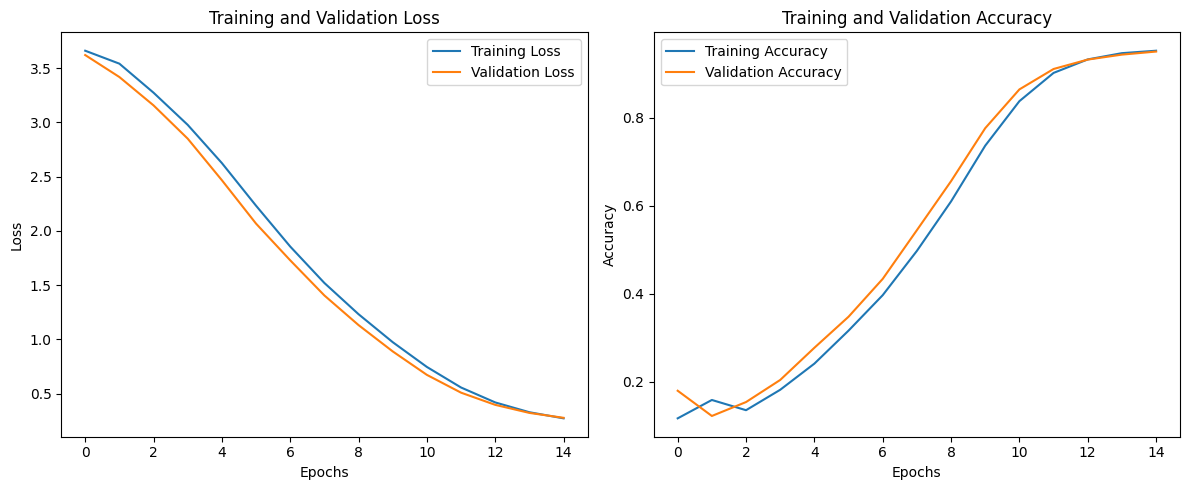

In [5]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


In [6]:

def generate_music(model, start_sequence, num_generated_notes=40):

    current = start_sequence.copy()
    generated = []

    for _ in range(num_generated_notes):

        pred = model.predict(current, verbose=0)

        next_note = np.argmax(pred[:, -1, :], axis=-1)

        generated.append(int(next_note[0]))

        new_note_one_hot = to_categorical(
            next_note,
            num_classes=40
        )[:, np.newaxis, :]

        current = np.concatenate(
            [current[:, 1:, :], new_note_one_hot],
            axis=1
        )

    return generated



start_sequence = np.random.randint(0, 40, size=(1, 24))

start_sequence = to_categorical(
    start_sequence,
    num_classes=40
)

generated_notes = generate_music(
    model,
    start_sequence,
    num_generated_notes=40
)

print("Generated notes:", generated_notes)


Generated notes: [26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26]


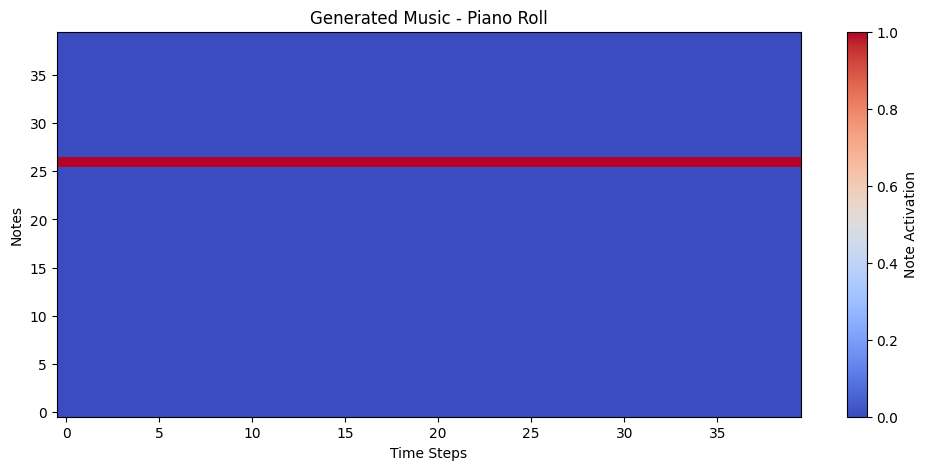

In [7]:

piano_roll = np.zeros((40, 40))

for t, note in enumerate(generated_notes):
    piano_roll[note, t] = 1

plt.figure(figsize=(12, 5))

plt.imshow(
    piano_roll,
    aspect='auto',
    cmap='coolwarm',
    origin='lower'
)

plt.title('Generated Music - Piano Roll')
plt.xlabel('Time Steps')
plt.ylabel('Notes')

plt.colorbar(label='Note Activation')

plt.show()
